# 04 · Complaints Forecast — next 15 days

<div dir="rtl">

**الهدف:** نتوقع عدد الشكاوى لكل نوع من الـ 15 نوع، لكل يوم من الـ 15 يوم الجايين، بناءً على آخر 30 يوم.

**المسابقة:** 3 طرق بيتوقعوا نفس الحاجة، وبنشوف مين أقرب للحقيقة:

1. **الطريقة البسيطة (Baseline):** متوسط نفس اليوم في آخر 4 أسابيع.
2. **LightGBM:** موديل بيتدرب على شكاوى مدينتنا.
3. **Chronos-Bolt (Amazon):** موديل جاهز متدرب مسبقًا على ملايين السلاسل الزمنية، وبيتوقع من غير تدريب.

**الامتحان:** الموديل مايشوفش ديسمبر وهو بيتدرب. بنديله آخر 30 يوم قبل الامتحان، ونقارن توقعه بالحقيقي، وده بيحصل مرتين: 1–15 ديسمبر و17–31 ديسمبر.

الداتا مصطنعة للتدريب، فالأرقام بتثبت إن الطريقة شغالة، مش إن الموديل جاهز لمدينة حقيقية.

</div>

## 1 · Setup
<div dir="rtl">

المكتبات اللي محتاجينها، والإعدادات الأساسية: الشباك 30 يوم، والتوقع 15 يوم، والتدريب من أول يوليو.

</div>

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy.stats import poisson

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DATA = Path.cwd() / "data"                                       # bundled copy (handoff package)
if not (DATA / "req_prepared.parquet").exists():
    DATA = Path.cwd().parent / "oasis_mob_pss" / "data_clean"   # forecast folder sitting next to oasis_mob_pss
OUT = Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)

WINDOW = 30                               # days the model looks back at
HORIZON = 15                              # days it predicts ahead
TRAIN_START = pd.Timestamp("2025-07-01")  # first full month after the app launch (DQ-10)
SEED = 42

## 2 · Load the complaints and count them per day
<div dir="rtl">

بنقرا ملف الشكاوى، ونعد كام شكوى جت من كل نوع في كل يوم. اليوم اللي مجاش فيه شكوى من نوع معين بياخد **صفر** مش بيتشال، لأن الصفر معلومة كمان.

</div>

In [2]:
req = pd.read_parquet(DATA / "req_prepared.parquet", columns=["date", "category_id", "pillar"])
req["date"] = pd.to_datetime(req["date"])
cal = pd.read_parquet(DATA / "calendar.parquet")
cal["date"] = pd.to_datetime(cal["date"])

all_days = pd.date_range("2025-01-01", "2025-12-31", freq="D")
daily = req.groupby(["date", "category_id"]).size().unstack(fill_value=0).reindex(all_days, fill_value=0)
CATS = list(daily.columns)
PILLAR = req.drop_duplicates("category_id").set_index("category_id")["pillar"]

print(f"{len(req):,} complaints · {len(CATS)} types · {daily.index.min():%d %b} to {daily.index.max():%d %b %Y}")
daily.loc[TRAIN_START:].describe().T[["mean", "std", "min", "max"]].round(1).sort_values("mean", ascending=False)

44,817 complaints · 15 types · 01 Jan to 31 Dec 2025


,mean,std,min,max
category_id,,,,
waste_overflow,18.1,5.0,8.0,32.0
streetlights,16.5,4.6,4.0,30.0
cleanliness,14.9,4.2,5.0,25.0
water_leak,14.6,4.2,5.0,28.0
roads,13.7,4.4,3.0,29.0
parking,13.3,3.9,4.0,25.0
noise,11.5,3.5,2.0,20.0
water_outage,10.2,3.4,3.0,21.0
power_outage,8.5,3.0,2.0,17.0


## 3 · Look at the data first
<div dir="rtl">

قبل أي موديل لازم نشوف الداتا بعينينا. الشارت الأول بيوري إجمالي الشكاوى في اليوم على السنة كلها، والتاني بيوري النمط الأسبوعي.

**اللي المفروض تلاحظه:** قفزة كبيرة بعد إطلاق التطبيق في يونيو. عشان كده بنتدرب من يوليو بس، لأن الشهور اللي قبله بتوصف مدينة مختلفة.

</div>

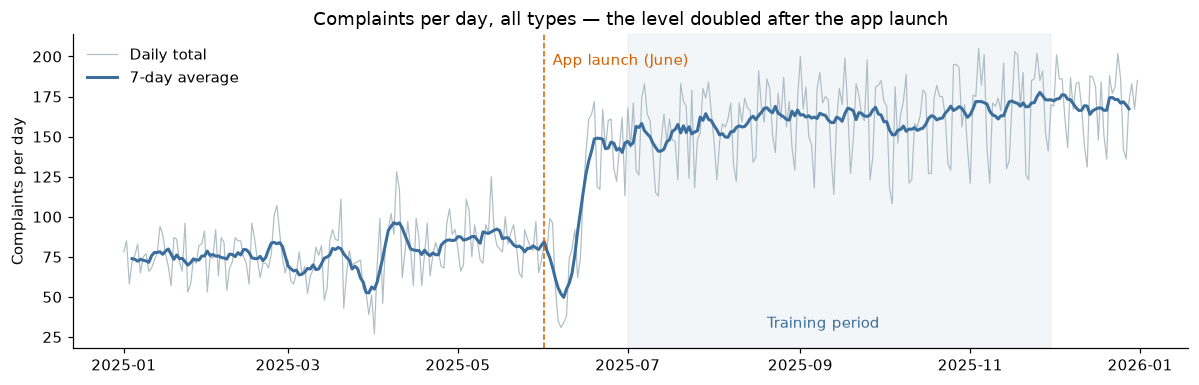

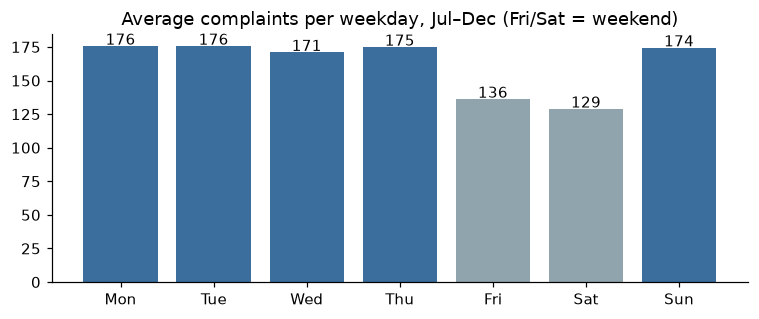

In [3]:
total = daily.sum(axis=1)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(total.index, total, color="#B0BEC5", lw=0.8, label="Daily total")
ax.plot(total.index, total.rolling(7, center=True).mean(), color="#3B6E9C", lw=2, label="7-day average")
ax.axvline(pd.Timestamp("2025-06-01"), color="#D55E00", ls="--", lw=1)
ax.text(pd.Timestamp("2025-06-04"), total.max() * 0.95, "App launch (June)", color="#D55E00")
ax.axvspan(TRAIN_START, pd.Timestamp("2025-11-30"), color="#3B6E9C", alpha=0.06)
ax.text(pd.Timestamp("2025-08-20"), total.max() * 0.15, "Training period", color="#3B6E9C")
ax.set_title("Complaints per day, all types — the level doubled after the app launch")
ax.set_ylabel("Complaints per day"); ax.legend(loc="upper left", frameon=False)
plt.tight_layout(); plt.show()

recent = daily.loc[TRAIN_START:].sum(axis=1)
by_dow = recent.groupby(recent.index.dayofweek).mean()
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(names, by_dow.values, color=["#3B6E9C" if d < 4 or d == 6 else "#90A4AE" for d in by_dow.index])
for i, v in enumerate(by_dow.values):
    ax.text(i, v + 1, f"{v:.0f}", ha="center")
ax.set_title("Average complaints per weekday, Jul–Dec (Fri/Sat = weekend)")
plt.tight_layout(); plt.show()

## 4 · The calendar for any day
<div dir="rtl">

دي الحاجات اللي **معروفة قبلها** عن أي يوم في المستقبل، فمسموح الموديل يستخدمها: يوم الأسبوع، وهل هو أجازة نهاية أسبوع (الجمعة والسبت)، وهل هو أجازة رسمية.

**تنبيه:** فترة التدريب (يوليو–نوفمبر) فيها 3 أجازات رسمية بس ومفيهاش رمضان، فالموديل مش هيتعلم أثر الأجازات كويس. والأجازات دي "افتراض الفريق" (DQ-06).

</div>

In [4]:
HOLIDAYS = set(cal.loc[cal["is_holiday"], "date"])
HOLIDAYS |= {pd.Timestamp("2026-01-07")}   # Coptic Christmas 2026, same team calendar rule as 2025

def day_info(d):
    return {"dow": d.dayofweek, "is_weekend": int(d.dayofweek in (4, 5)), "is_holiday": int(d in HOLIDAYS)}

print("Holidays inside the training period:", sorted(d.strftime("%d %b") for d in HOLIDAYS if TRAIN_START <= d <= pd.Timestamp("2025-11-30")))

Holidays inside the training period: ['04 Sep', '06 Oct', '23 Jul']


## 5 · Method 1: the simple baseline
<div dir="rtl">

**الفكرة:** "الخميس الجاي هيبقى زي متوسط آخر 4 خميس". مفيهاش أي ذكاء، ودي المسطرة اللي بنقيس عليها. لو الموديل مغلبهاش يبقى ملوش لازمة.

يوم التوقف (cutoff) هو آخر يوم عندنا داتا فيه. كل الحسابات بتستخدم الـ 30 يوم اللي قبله بس.

</div>

In [5]:
def baseline_forecast(cutoff):
    # Average of the same weekday in the last 4 weeks, using only days up to the cutoff.
    rows = []
    for h in range(1, HORIZON + 1):
        target = cutoff + pd.Timedelta(days=h)
        same = [target - pd.Timedelta(days=7 * k) for k in range(1, 4 + 3)]
        same = [d for d in same if d <= cutoff][:4]
        for c in CATS:
            rows.append({"cutoff": cutoff, "date": target, "h": h, "category_id": c,
                         "pred": daily.loc[same, c].mean()})
    return pd.DataFrame(rows)

baseline_forecast(pd.Timestamp("2025-11-30")).head()

,cutoff,date,h,category_id,pred
0,2025-11-30,2025-12-01,1,app,3.75
1,2025-11-30,2025-12-01,1,cleanliness,20.00
2,2025-11-30,2025-12-01,1,hvac,6.25
3,2025-11-30,2025-12-01,1,noise,12.75
4,2025-11-30,2025-12-01,1,parking,17.25


## 6 · Method 2: LightGBM — build the training examples
<div dir="rtl">

**المثال الواحد** = يوم توقف + نوع شكوى + يوم في المستقبل (من 1 لـ 15). الموديل بيشوف ملخص الـ 30 يوم اللي قبل يوم التوقف، ومعلومات اليوم المطلوب، والإجابة الصح معروفة من الداتا.

**الشباك بيتزحلق يوم يوم:** أول يوم توقف 30 يوليو (يبص على 1–30 يوليو)، وآخر يوم توقف 15 نوفمبر (عشان الـ 15 يوم اللي بعده يخلصوا في نوفمبر). كده عندنا 109 يوم توقف × 15 نوع × 15 يوم.

**القاعدة الذهبية:** أي معلومة عن الشكاوى لازم تكون **قبل** يوم التوقف. وهو بيتوقع اليوم العاشر، مايعرفش شكاوى اليوم التاسع، لأنها في الحقيقة لسه ماحصلتش.

| المعلومة | معناها |
|---|---|
| `category_id` | نوع الشكوى |
| `h` | بعد كام يوم من يوم التوقف (1–15) |
| `dow`, `is_weekend`, `is_holiday` | معلومات اليوم المطلوب |
| `mean_7`, `mean_30` | متوسط آخر 7 و30 يوم |
| `std_30` | قد إيه الأرقام بتتقلب |
| `same_dow_4w` | متوسط نفس اليوم في آخر 4 أسابيع |
| `trend` | `mean_7 / mean_30`: الشكاوى طالعة ولا نازلة |
| `weekend_ratio` | الويك إند أقل من باقي الأيام بقد إيه في النوع ده |

</div>

In [6]:
def make_examples(cutoff):
    window = daily.loc[cutoff - pd.Timedelta(days=WINDOW - 1): cutoff]
    weekend = window.index.dayofweek.isin([4, 5])
    rows = []
    for c in CATS:
        s = window[c]
        m7, m30 = s.iloc[-7:].mean(), s.mean()
        wk_ratio = (s[weekend].mean() + 0.5) / (s[~weekend].mean() + 0.5)
        for h in range(1, HORIZON + 1):
            target = cutoff + pd.Timedelta(days=h)
            same = [target - pd.Timedelta(days=7 * k) for k in range(1, 4 + 3)]
            same = [d for d in same if d <= cutoff][:4]
            rows.append({"cutoff": cutoff, "date": target, "h": h, "category_id": c,
                         **day_info(target),
                         "mean_7": m7, "mean_30": m30, "std_30": s.std(),
                         "same_dow_4w": s.loc[same].mean(), "trend": (m7 + 0.5) / (m30 + 0.5),
                         "weekend_ratio": wk_ratio,
                         "y": daily.at[target, c] if target in daily.index else np.nan})
    return pd.DataFrame(rows)

FEATURES = ["category_id", "h", "dow", "is_weekend", "is_holiday", "mean_7", "mean_30",
            "std_30", "same_dow_4w", "trend", "weekend_ratio"]

def examples_between(first_cutoff, last_cutoff):
    cutoffs = pd.date_range(first_cutoff, last_cutoff, freq="D")
    df = pd.concat([make_examples(c) for c in cutoffs], ignore_index=True)
    df["category_id"] = pd.Categorical(df["category_id"], categories=CATS)
    return df

FIRST_CUTOFF = TRAIN_START + pd.Timedelta(days=WINDOW - 1)    # 30 Jul: first day with a full 30-day window
train_1 = examples_between(FIRST_CUTOFF, pd.Timestamp("2025-11-15"))
print(f"Exam 1 training set: {train_1['cutoff'].nunique()} cutoffs × {len(CATS)} types × {HORIZON} days = {len(train_1):,} examples")
train_1.head()

Exam 1 training set: 109 cutoffs × 15 types × 15 days = 24,525 examples


,cutoff,date,h,category_id,dow,is_weekend,is_holiday,mean_7,mean_30,std_30,same_dow_4w,trend,weekend_ratio,y
0,2025-07-30,2025-07-31,1,app,3,0,0,5.142857,4.833333,2.118609,5.00,1.058036,0.77,3
1,2025-07-30,2025-08-01,2,app,4,1,0,5.142857,4.833333,2.118609,3.00,1.058036,0.77,3
2,2025-07-30,2025-08-02,3,app,5,1,0,5.142857,4.833333,2.118609,4.75,1.058036,0.77,7
3,2025-07-30,2025-08-03,4,app,6,0,0,5.142857,4.833333,2.118609,4.25,1.058036,0.77,5
4,2025-07-30,2025-08-04,5,app,0,0,0,5.142857,4.833333,2.118609,6.75,1.058036,0.77,4


## 7 · Method 2: LightGBM — train
<div dir="rtl">

**الإعدادات:**
- `objective="poisson"`: لأن اللي بنتوقعه **عدد** صغير مايبقاش سالب.
- 400 شجرة بمعدل تعلم 0.03، وكل شجرة صغيرة (15 ورقة)، عشان الموديل مايحفظش الداتا.
- `category_id` بيتعامل معاه كنوع مش كرقم.

</div>

In [7]:
PARAMS = {"objective": "poisson", "learning_rate": 0.03, "num_leaves": 15, "min_data_in_leaf": 40,
          "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 1, "lambda_l2": 1.0,
          "seed": SEED, "verbose": -1}
N_TREES = 400

def train_lgb(train_df):
    ds = lgb.Dataset(train_df[FEATURES], label=train_df["y"], categorical_feature=["category_id"])
    return lgb.train(PARAMS, ds, num_boost_round=N_TREES)

model_1 = train_lgb(train_1)
print("Trained", model_1.num_trees(), "trees")

Trained 400 trees


## 8 · Method 3: Chronos-Bolt (pretrained, no training)
<div dir="rtl">

**Chronos-Bolt-Small** من Amazon: حوالي 48 مليون باراميتر، متدرب مسبقًا على سلاسل زمنية كتير. بنديله آخر 30 يوم لكل نوع، ويطلع 15 يوم. هو مابيعرفش الأجازات ولا يوم الأسبوع غير من شكل الأرقام نفسها.

محتاج مكتبتين: `torch` و`chronos-forecasting`، وأول مرة بينزّل الموديل من الإنترنت (حوالي 200 ميجا). لو مش متسطبين، الخلية دي بتتخطى والنوت بوك يكمل بالطريقتين التانيين.

</div>

In [8]:
try:
    import torch
    from chronos import BaseChronosPipeline
    chronos = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small", device_map="cpu", torch_dtype=torch.float32)
    CHRONOS_OK = True
    print("Chronos-Bolt-Small loaded")
except Exception as e:
    CHRONOS_OK = False
    print("Chronos skipped:", type(e).__name__, str(e)[:160])

def chronos_forecast(cutoff):
    window = daily.loc[cutoff - pd.Timedelta(days=WINDOW - 1): cutoff]
    context = torch.tensor(window[CATS].T.values, dtype=torch.float32)          # 15 series × 30 days
    q, _ = chronos.predict_quantiles(context, prediction_length=HORIZON, quantile_levels=[0.1, 0.5, 0.9])
    rows = []
    for i, c in enumerate(CATS):
        for h in range(1, HORIZON + 1):
            lo, med, hi = (max(0.0, float(v)) for v in q[i, h - 1])
            rows.append({"cutoff": cutoff, "date": cutoff + pd.Timedelta(days=h), "h": h, "category_id": c,
                         "pred": med, "low": lo, "high": hi})
    return pd.DataFrame(rows)

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Chronos-Bolt-Small loaded


## 9 · The exam: December
<div dir="rtl">

**امتحانين:**
- **امتحان 1:** يوم التوقف 30 نوفمبر ← يتوقع 1–15 ديسمبر. الموديل اتدرب على أيام توقف لحد 15 نوفمبر.
- **امتحان 2:** يوم التوقف 16 ديسمبر ← يتوقع 17–31 ديسمبر. الموديل بيتدرب تاني على أيام توقف لحد 1 ديسمبر، زي ما هيحصل في الحقيقة لما ييجي شهر جديد.

**المقاييس:**
- **MAE:** متوسط الفرق بين المتوقع والحقيقي بالشكاوى. الأقل أحسن.
- **دقة التوقع** = 100% − WAPE، وWAPE = مجموع الأخطاء ÷ مجموع الشكاوى الحقيقية.
- **تغطية المدى:** المدى (من كام لكام) المفروض يحتوي الرقم الحقيقي في حوالي 80% من الأيام.

</div>

In [9]:
EXAMS = [
    {"name": "Exam 1 (1–15 Dec)", "cutoff": pd.Timestamp("2025-11-30"), "last_train_cutoff": pd.Timestamp("2025-11-15")},
    {"name": "Exam 2 (17–31 Dec)", "cutoff": pd.Timestamp("2025-12-16"), "last_train_cutoff": pd.Timestamp("2025-12-01")},
]

def actual_for(df):
    return df.assign(actual=[daily.at[d, c] for d, c in zip(df["date"], df["category_id"])])

results = []
for ex in EXAMS:
    model = model_1 if ex["cutoff"] == EXAMS[0]["cutoff"] else train_lgb(examples_between(FIRST_CUTOFF, ex["last_train_cutoff"]))
    test = make_examples(ex["cutoff"])
    test["category_id"] = pd.Categorical(test["category_id"], categories=CATS)
    mu = model.predict(test[FEATURES])
    lgb_df = test[["cutoff", "date", "h", "category_id"]].assign(
        pred=mu, low=poisson.ppf(0.1, mu), high=poisson.ppf(0.9, mu), method="LightGBM")
    parts = [baseline_forecast(ex["cutoff"]).assign(method="Baseline"), lgb_df]
    if CHRONOS_OK:
        parts.append(chronos_forecast(ex["cutoff"]).assign(method="Chronos-Bolt"))
    for p in parts:
        p["category_id"] = p["category_id"].astype(str)
        results.append(actual_for(p).assign(exam=ex["name"]))

res = pd.concat(results, ignore_index=True)
res["abs_err"] = (res["pred"] - res["actual"]).abs()

def score(g):
    out = {"MAE (complaints/day)": g["abs_err"].mean(),
           "Forecast accuracy %": 100 * (1 - g["abs_err"].sum() / g["actual"].sum())}
    out["Range coverage %"] = (100 * ((g["actual"] >= g["low"]) & (g["actual"] <= g["high"])).mean()
                               if g["low"].notna().all() else np.nan)
    return pd.Series(out)

def score_table(keys):
    by = keys[0] if len(keys) == 1 else keys
    return pd.DataFrame({k: score(g) for k, g in res.groupby(by)}).T.rename_axis(by)

order = ["Baseline", "LightGBM", "Chronos-Bolt"]
by_exam = score_table(["exam", "method"]).round(2)
overall = score_table(["method"]).round(2).reindex([m for m in order if m in res["method"].unique()])
display(by_exam)
overall

MAE (complaints/day)  Forecast accuracy %  Range coverage %
exam               method                                                                   
Exam 1 (1–15 Dec)  Baseline                      2.74                76.14               NaN
                   Chronos-Bolt                  2.68                76.66             89.78
                   LightGBM                      2.51                78.15             85.33
Exam 2 (17–31 Dec) Baseline                      3.01                73.31               NaN
                   Chronos-Bolt                  2.91                74.19             87.56
                   LightGBM                      2.81                75.12             82.22

,MAE (complaints/day),Forecast accuracy %,Range coverage %
method,,,
Baseline,2.88,74.74,NaN
LightGBM,2.66,76.65,83.78
Chronos-Bolt,2.80,75.44,88.67


<div dir="rtl">

**إزاي تقرا الجدول:** الطريقة اللي الـ MAE بتاعها أقل والدقة أعلى في **الامتحانين الاتنين** هي اللي نعتمدها. لو LightGBM مكسبش الطريقة البسيطة بفرق واضح، نقول كده بصراحة.

</div>

### Accuracy at different levels
<div dir="rtl">

ده **نفس الموديل ونفس توقعات ديسمبر**، بس بنجمعها قبل ما نقارنها بالحقيقي. لكل نوع في كل يوم، الصدفة بتأثر جامد (حوالي ±3 شكاوى)، فالدقة ~77%، وده قريب من أقصى حد ممكن.
لما بنجمع الـ 15 يوم لكل نوع، أو الـ 15 نوع لكل يوم، الزيادة والنقص بيعوّضوا بعض، فالدقة بتطلع أعلى (~93–94%).

</div>

In [10]:
def accuracy_at(keys):
    # Sum predictions and actuals up to the level first, then score: 100% - WAPE.
    g = res.groupby(["method", "exam"] + keys)[["pred", "actual"]].sum()
    return g.groupby(level="method").apply(lambda x: 100 * (1 - (x["pred"] - x["actual"]).abs().sum() / x["actual"].sum()))

levels = pd.DataFrame({
    "Each type, each day": accuracy_at(["category_id", "date"]),
    "Each type, 15-day total": accuracy_at(["category_id"]),
    "Whole city, each day": accuracy_at(["date"]),
}).T.round(1)
levels.columns.name = "Forecast accuracy %"
levels[[m for m in order if m in levels.columns]]

Forecast accuracy %,Baseline,LightGBM,Chronos-Bolt
"Each type, each day",74.7,76.7,75.4
"Each type, 15-day total",92.5,93.1,92.6
"Whole city, each day",94.0,93.9,90.4


## 10 · Which types are easy and which are hard
<div dir="rtl">

الدقة لكل نوع شكوى لوحده، على الامتحانين مع بعض. الأنواع اللي شكاويها قليلة في اليوم (زي التطبيق والتكييف) دقتها بتبقى أقل، لأن الفرق بين 2 و4 شكاوى صدفة أكتر منه نمط.

</div>

In [11]:
per_type = (score_table(["category_id", "method"])["Forecast accuracy %"]
            .unstack()[[m for m in order if m in res["method"].unique()]])
per_type.insert(0, "avg/day", [daily.loc[TRAIN_START:, c].mean() for c in per_type.index])
per_type.round(1).sort_values("avg/day", ascending=False)

method,avg/day,Baseline,LightGBM,Chronos-Bolt
category_id,,,,
waste_overflow,18.1,79.8,82.0,80.4
streetlights,16.5,79.9,83.9,80.3
cleanliness,14.9,79.9,82.3,81.4
water_leak,14.6,78.7,79.1,80.9
roads,13.7,71.3,72.6,71.9
parking,13.3,75.4,75.6,73.3
noise,11.5,67.8,72.7,74.7
water_outage,10.2,70.1,73.9,70.8
power_outage,8.5,71.3,77.1,77.2


## 11 · Predicted vs actual in December
<div dir="rtl">

الخط الرمادي هو الحقيقي، والأزرق توقع LightGBM، والمساحة الفاتحة هي المدى المتوقع. الخط المتقطع البرتقالي هو الطريقة البسيطة.

</div>

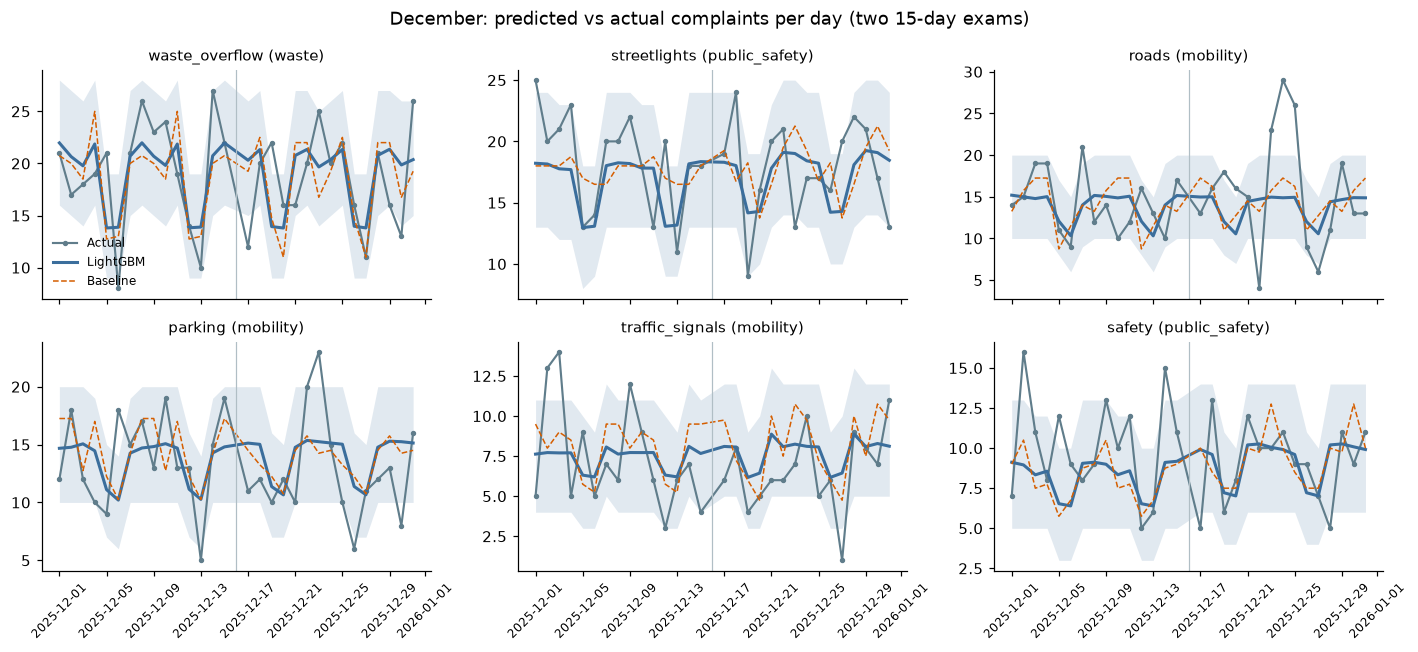

In [12]:
show = ["waste_overflow", "streetlights", "roads", "parking", "traffic_signals", "safety"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
for ax, c in zip(axes.flat, show):
    a = res[(res["category_id"] == c) & (res["method"] == "LightGBM")].sort_values("date")
    b = res[(res["category_id"] == c) & (res["method"] == "Baseline")].sort_values("date")
    ax.fill_between(a["date"], a["low"], a["high"], color="#3B6E9C", alpha=0.15, lw=0)
    ax.plot(a["date"], a["actual"], color="#607D8B", lw=1.4, marker="o", ms=2.5, label="Actual")
    ax.plot(a["date"], a["pred"], color="#3B6E9C", lw=2, label="LightGBM")
    ax.plot(b["date"], b["pred"], color="#D55E00", lw=1, ls="--", label="Baseline")
    ax.axvline(pd.Timestamp("2025-12-16"), color="#B0BEC5", lw=0.8)
    ax.set_title(f"{c} ({PILLAR[c]})", fontsize=10)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("December: predicted vs actual complaints per day (two 15-day exams)")
plt.tight_layout(); plt.show()

## 12 · What the model relies on
<div dir="rtl">

**Feature Importance:** أنهي معلومة الموديل استخدمها أكتر وهو بيقرر. ده بيخلينا نشرح الموديل في البرزنتيشن بدل ما يبقى صندوق أسود.

</div>

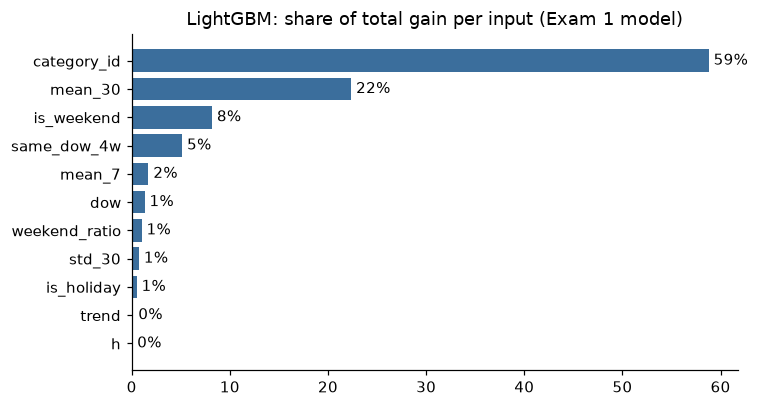

In [13]:
imp = pd.Series(model_1.feature_importance("gain"), index=FEATURES)
imp = (100 * imp / imp.sum()).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(imp.index, imp.values, color="#3B6E9C")
for i, v in enumerate(imp.values):
    ax.text(v + 0.5, i, f"{v:.0f}%", va="center")
ax.set_title("LightGBM: share of total gain per input (Exam 1 model)")
plt.tight_layout(); plt.show()

## 13 · The real forecast: 1–15 January 2026
<div dir="rtl">

دلوقتي بنتدرب على **كل** الداتا من يوليو لديسمبر (آخر يوم توقف 16 ديسمبر)، وبنتوقع من يوم التوقف 31 ديسمبر ← أول 15 يوم في يناير 2026. ده التوقع اللي ممكن يتعرض في الداشبورد أو المدينة 3D.

7 يناير (عيد الميلاد) متعلم إنه أجازة، بنفس قاعدة تقويم الفريق في 2025.

</div>

In [14]:
final_model = train_lgb(examples_between(FIRST_CUTOFF, pd.Timestamp("2025-12-16")))
future = make_examples(pd.Timestamp("2025-12-31"))
future["category_id"] = pd.Categorical(future["category_id"], categories=CATS)
mu = final_model.predict(future[FEATURES])
forecast = future[["date", "category_id"]].assign(
    category_id=lambda d: d["category_id"].astype(str),
    pillar=lambda d: d["category_id"].map(PILLAR),
    forecast=np.round(mu, 1), low_80=poisson.ppf(0.1, mu).astype(int), high_80=poisson.ppf(0.9, mu).astype(int),
    model="LightGBM (poisson), trained on Jul–Dec 2025, synthetic data")
forecast.to_csv(OUT / "forecast_2026-01-01_to_15.csv", index=False)
res.to_csv(OUT / "december_backtest.csv", index=False)

table = forecast.pivot(index="date", columns="category_id", values="forecast")
table.index = table.index.strftime("%a %d %b")
table["TOTAL"] = table.sum(axis=1)
print("Saved:", OUT / "forecast_2026-01-01_to_15.csv")
table.round(0).astype(int)

Saved: C:\Users\NoteBook\Downloads\Capital Project\forecast\outputs\forecast_2026-01-01_to_15.csv


category_id,app,cleanliness,hvac,noise,parking,parks,power_outage,roads,safety,sewer,streetlights,traffic_signals,waste_overflow,water_leak,water_outage,TOTAL
date,,,,,,,,,,,,,,,,
Thu 01 Jan,6,16,6,12,14,8,9,15,10,10,18,8,20,16,11,179
Fri 02 Jan,5,12,5,9,11,7,7,12,8,8,14,6,14,13,8,138
Sat 03 Jan,5,11,4,9,11,6,7,11,7,7,14,6,14,13,8,133
Sun 04 Jan,6,16,6,12,14,8,10,14,10,10,19,8,20,17,11,179
Mon 05 Jan,5,16,5,12,15,7,10,14,11,9,19,8,20,16,11,179
Tue 06 Jan,5,17,5,12,15,8,10,15,11,10,18,8,19,16,11,180
Wed 07 Jan,6,12,6,13,13,7,9,12,9,9,15,6,16,15,10,157
Thu 08 Jan,6,16,6,12,14,8,9,15,10,10,18,8,20,16,11,180
Fri 09 Jan,5,12,5,9,11,7,7,12,8,8,14,6,14,13,8,138


### Total per type over the 15 days
<div dir="rtl">

نفس التوقع اللي فوق، بس مجموع الـ 15 يوم لكل نوع، ومعاه إجمالي المدينة كلها. المدى (من–لـ) هو مدى الـ 80%. دقة الإجمالي ده في امتحان ديسمبر ~93%، مقابل ~77% لليوم الواحد (الجدول في خطوة 9).

</div>

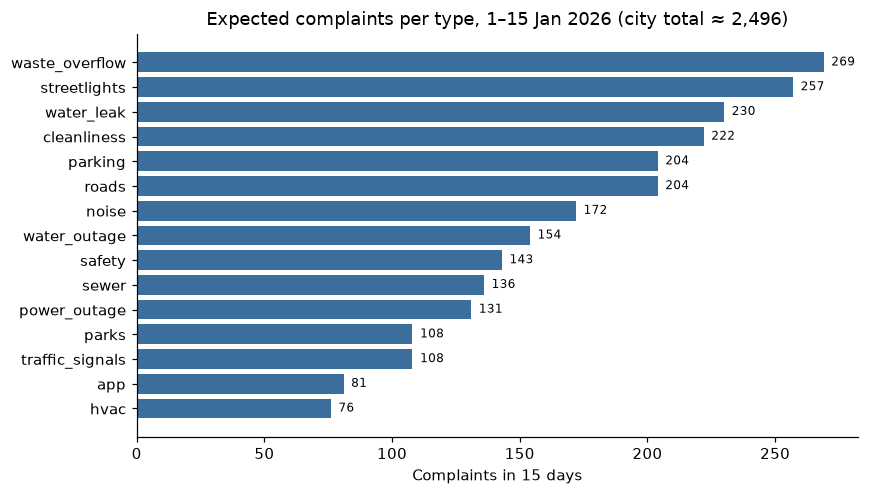

Saved: C:\Users\NoteBook\Downloads\Capital Project\forecast\outputs\forecast_15day_totals.csv


,pillar,forecast_15d,low_80,high_80
category_id,,,,
waste_overflow,waste,269,248,290
streetlights,public_safety,257,237,278
water_leak,water,230,211,250
cleanliness,waste,222,203,241
parking,mobility,204,186,223
roads,mobility,204,186,222
noise,environment,172,156,189
water_outage,water,154,138,170
safety,public_safety,143,128,158


In [15]:
tot = pd.Series(mu, index=future["category_id"].astype(str)).groupby(level=0).sum().sort_values(ascending=False)
totals = pd.DataFrame({"pillar": tot.index.map(PILLAR), "forecast_15d": tot.round(0).astype(int),
                       "low_80": poisson.ppf(0.1, tot).astype(int), "high_80": poisson.ppf(0.9, tot).astype(int)},
                      index=tot.index.rename("category_id"))
city = tot.sum()
totals.loc["TOTAL"] = ["all", int(round(city)), int(poisson.ppf(0.1, city)), int(poisson.ppf(0.9, city))]
totals.to_csv(OUT / "forecast_15day_totals.csv")

t = totals.drop("TOTAL")
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(t.index[::-1], t["forecast_15d"][::-1], color="#3B6E9C")
for i, v in enumerate(t["forecast_15d"][::-1]):
    ax.text(v + 3, i, f"{v}", va="center", fontsize=8)
ax.set_title(f"Expected complaints per type, 1–15 Jan 2026 (city total ≈ {int(round(city)):,})")
ax.set_xlabel("Complaints in 15 days")
plt.tight_layout(); plt.show()

print("Saved:", OUT / "forecast_15day_totals.csv")
totals

In [16]:
import json
from importlib.metadata import version

# Save the final model's weights (all trees) in LightGBM's own text format, plus a model card with what is needed to use it.
OUT_MODEL = Path.cwd() / "model"
OUT_MODEL.mkdir(exist_ok=True)
final_model.save_model(str(OUT_MODEL / "lightgbm_complaints_forecast.txt"))
card = {
    "model_file": "lightgbm_complaints_forecast.txt",
    "objective": "poisson",
    "params": PARAMS, "num_trees": final_model.num_trees(),
    "features": FEATURES,
    "categorical_feature": "category_id",
    "category_order": CATS,   # category_id must be pd.Categorical with exactly this order (codes 0..14)
    "pillar": PILLAR[CATS].to_dict(),
    "window_days": WINDOW, "horizon_days": HORIZON,
    "training_cutoffs": [str(FIRST_CUTOFF.date()), "2025-12-16"],
    "forecast_cutoff": "2025-12-31",
    "weekend_dows": [4, 5],
    "holidays": sorted(str(d.date()) for d in HOLIDAYS),
    "output": "expected complaints per type per day (poisson mean); 80% range = poisson.ppf(0.1 / 0.9, mean)",
    "versions": {p: version(p) for p in ["lightgbm", "pandas", "numpy", "scipy", "pyarrow"]},
}
(OUT_MODEL / "model_card.json").write_text(json.dumps(card, indent=2), encoding="utf-8")

# Check: the saved file reproduces the same forecast.
reloaded = lgb.Booster(model_file=str(OUT_MODEL / "lightgbm_complaints_forecast.txt"))
print("Saved weights:", OUT_MODEL / "lightgbm_complaints_forecast.txt")
print("Reloaded model gives identical forecast:", np.allclose(reloaded.predict(future[FEATURES]), mu))

Saved weights: C:\Users\NoteBook\Downloads\Capital Project\forecast\model\lightgbm_complaints_forecast.txt
Reloaded model gives identical forecast: True


## 14 · Summary
<div dir="rtl">

- **بنتوقع:** عدد الشكاوى لكل نوع (15 نوع) لكل يوم من الـ 15 يوم الجايين، من آخر 30 يوم.
- **اتدربنا:** على يوليو–نوفمبر، بعد إطلاق التطبيق، بشباك بيتزحلق يوم يوم.
- **اتمتحنا:** على ديسمبر مرتين، وقارنّا الطريقة البسيطة بـ LightGBM (وChronos لو مكتبته متسطبة) بالـ MAE ودقة التوقع (الجدول في خطوة 9).
- **الحدود:** الداتا مصطنعة، وفترة التدريب فيها 3 أجازات بس ومفيهاش رمضان، فالموديل محتاج سنة كاملة بعد التطبيق عشان يتعلم المواسم. الأنواع القليلة (أقل من 5 شكاوى في اليوم) توقعها أضعف.
- **الملفات:** `outputs/forecast_2026-01-01_to_15.csv` و`outputs/december_backtest.csv`.

</div>

# Part 2 · Zone-level forecast (where the complaints come from)
<div dir="rtl">

**الهدف:** تختار **منطقة** (Z01–Z06 أو كل المناطق) و**عدد أيام** من 1 لـ 15، والنظام يقولك هييجي كام شكوى من كل نوع في المنطقة دي، يوم بيوم، ومعاهم الإجمالي.

**الخطة:** نعد الشكاوى لكل منطقة × نوع × يوم (6 × 15 = 90 سلسلة)، ونقارن 3 طرق على **4 امتحانات** (نوفمبر وديسمبر)، ونحسب الدقة لكل عدد أيام من 1 لـ 15، ونختار الأحسن. بعدها نطلّع توقع يناير، ونعمل دالة `get_forecast(zone, days)`.

الجزء الأول (المدينة كلها) زي ما هو، ومحصلوش أي تغيير.

</div>

## 15 · Count complaints per zone × type × day
<div dir="rtl">

نفس العد اللي في خطوة 2، بس بنضيف المنطقة (`zone_id`). وبنتأكد إن مجموع المناطق = أرقام المدينة بالظبط.

**ملاحظة مهمة:** المناطق مش زي بعض. Z01 وZ02 وZ05 كل واحدة فيها ~40–45 شكوى في اليوم، لكن Z03 فيها ~5 بس. ومتوسط كل نوع في كل منطقة ~1.8 شكوى في اليوم، وده رقم صغير، فالصدفة هتأثر أكتر من مستوى المدينة.

</div>

In [17]:
reqz = pd.read_parquet(DATA / "req_prepared.parquet", columns=["date", "category_id", "zone_id"])
reqz["date"] = pd.to_datetime(reqz["date"])
print("Rows with missing zone_id:", int(reqz["zone_id"].isna().sum()))
reqz = reqz.dropna(subset=["zone_id"])
ZONES = sorted(reqz["zone_id"].unique())
NZ, NT = len(ZONES), len(CATS)

zidx = pd.MultiIndex.from_product([all_days, ZONES, CATS], names=["date", "zone_id", "category_id"])
Z = (reqz.groupby(["date", "zone_id", "category_id"]).size()
     .reindex(zidx, fill_value=0).to_numpy().reshape(len(all_days), NZ, NT))   # day × zone × type
DAY_POS = {d: i for i, d in enumerate(all_days)}
print("Check: zone counts add up to the city counts:", bool((Z.sum(axis=1) == daily[CATS].to_numpy()).all()))

zrecent = Z[DAY_POS[TRAIN_START]:]
zone_summary = pd.DataFrame({
    "complaints/day (Jul–Dec)": zrecent.sum(axis=2).mean(axis=0),
    "avg per type per day": zrecent.mean(axis=(0, 2)),
    "share of city %": 100 * zrecent.sum(axis=(0, 2)) / zrecent.sum(),
}, index=pd.Index(ZONES, name="zone_id")).round(1)
print(f"{NZ} zones × {NT} types = {NZ * NT} series")
zone_summary

Rows with missing zone_id: 0
Check: zone counts add up to the city counts: True
6 zones × 15 types = 90 series


,complaints/day (Jul–Dec),avg per type per day,share of city %
zone_id,,,
Z01,45.0,3.0,27.7
Z02,41.3,2.8,25.4
Z03,4.6,0.3,2.8
Z04,16.5,1.1,10.2
Z05,43.6,2.9,26.8
Z06,11.5,0.8,7.1


## 16 · The three zone methods and their inputs
<div dir="rtl">

بنقارن 3 طرق. وكلهم بيلتزموا بنفس القاعدة: **أي معلومة عن الشكاوى لازم تكون قبل يوم التوقف أو فيه.**

1. **Baseline:** متوسط نفس اليوم في آخر 4 أسابيع، لكل منطقة × نوع.
2. **LightGBM-zone:** موديل واحد لكل الـ 90 سلسلة، بنفس إعدادات موديل المدينة بالظبط (مش متظبط على الامتحان). بياخد نفس معلومات خطوة 6، محسوبة للمنطقة × النوع، ومعاها:
   - `zone_id`: المنطقة (كنوع مش رقم)
   - `city_mean_7` و`city_mean_30`: متوسط النوع ده في المدينة كلها
   - `zone_share_30`: نسبة المنطقة من النوع ده في آخر 30 يوم، (منطقة + 0.5) ÷ (مدينة + 0.5 × 6)
   - `zone_total_mean_30`: متوسط إجمالي شكاوى المنطقة في اليوم
3. **Top-down:** ناخد توقع موديل المدينة (LightGBM من الجزء الأول) لكل نوع، ونضربه في نسبة المنطقة من النوع ده في آخر 60 يوم.

</div>

In [18]:
ZFEATURES = ["zone_id", "category_id", "h", "dow", "is_weekend", "is_holiday",
             "mean_7", "mean_30", "std_30", "same_dow_4w", "trend", "weekend_ratio",
             "city_mean_7", "city_mean_30", "zone_share_30", "zone_total_mean_30"]
ZONE_GRID, TYPE_GRID = np.repeat(ZONES, NT), np.tile(CATS, NZ)   # row order: zone-major, then type

def zone_examples(cutoff):
    # Same leakage rule as the city model: every complaint feature uses days <= cutoff only.
    i = DAY_POS[cutoff]
    W = Z[i - WINDOW + 1: i + 1].astype(float)                      # 30 days × zone × type
    wk = all_days[i - WINDOW + 1: i + 1].day_of_week.isin([4, 5])
    m7, m30, sd = W[-7:].mean(0), W.mean(0), W.std(0, ddof=1)
    wr = (W[wk].mean(0) + 0.5) / (W[~wk].mean(0) + 0.5)
    city = W.sum(1)                                                 # 30 days × type
    share = (W.sum(0) + 0.5) / (city.sum(0) + 0.5 * NZ)             # zone's share of each type
    ztot = np.repeat(W.sum(2).mean(0), NT)                          # zone's total complaints/day
    parts = []
    for h in range(1, HORIZON + 1):
        target = cutoff + pd.Timedelta(days=h)
        same = [target - pd.Timedelta(days=7 * k) for k in range(1, 7)]
        same = [DAY_POS[d] for d in same if d <= cutoff][:4]
        y = Z[DAY_POS[target]].ravel().astype(float) if target in DAY_POS else np.nan
        parts.append(pd.DataFrame({
            "cutoff": cutoff, "date": target, "h": h, "zone_id": ZONE_GRID, "category_id": TYPE_GRID,
            **day_info(target),
            "mean_7": m7.ravel(), "mean_30": m30.ravel(), "std_30": sd.ravel(),
            "same_dow_4w": Z[same].mean(0).ravel(), "trend": ((m7 + 0.5) / (m30 + 0.5)).ravel(),
            "weekend_ratio": wr.ravel(),
            "city_mean_7": np.tile(city[-7:].mean(0), NZ), "city_mean_30": np.tile(city.mean(0), NZ),
            "zone_share_30": share.ravel(), "zone_total_mean_30": ztot, "y": y}))
    df = pd.concat(parts, ignore_index=True)
    df["zone_id"] = pd.Categorical(df["zone_id"], categories=ZONES)
    df["category_id"] = pd.Categorical(df["category_id"], categories=CATS)
    return df

# Build the examples for every training cutoff once; each exam then filters by cutoff.
ZX = pd.concat([zone_examples(c) for c in pd.date_range(FIRST_CUTOFF, "2025-12-16")], ignore_index=True)
print(f"Zone examples: {ZX['cutoff'].nunique()} cutoffs × {NZ * NT} series × {HORIZON} days = {len(ZX):,}")
ZX.head(3)

Zone examples: 140 cutoffs × 90 series × 15 days = 189,000


,cutoff,date,h,zone_id,category_id,dow,is_weekend,is_holiday,mean_7,mean_30,std_30,same_dow_4w,trend,weekend_ratio,city_mean_7,city_mean_30,zone_share_30,zone_total_mean_30,y
0,2025-07-30,2025-07-31,1,Z01,app,3,0,0,1.428571,1.500000,0.973795,1.75,0.964286,0.687500,5.142857,4.833333,0.307432,42.8,1.0
1,2025-07-30,2025-07-31,1,Z01,cleanliness,3,0,0,5.142857,4.200000,2.139932,5.50,1.200608,0.681416,14.428571,13.866667,0.301909,42.8,3.0
2,2025-07-30,2025-07-31,1,Z01,hvac,3,0,0,1.142857,1.733333,1.552158,1.50,0.735608,1.010204,9.285714,8.166667,0.211694,42.8,1.0


## 17 · The exam: 4 tests over November and December
<div dir="rtl">

بدل امتحانين، عملنا **4** على شهرين، عشان الرقم يبقى أوثق. في كل امتحان، الموديل بيتدرب بس على أيام توقف الـ 15 يوم اللي بعدها بيخلصوا قبل يوم الامتحان أو فيه.

| الامتحان | يوم التوقف | بيتوقع | آخر يوم توقف في التدريب |
|---|---|---|---|
| Nov A | 31 أكتوبر | 1–15 نوفمبر | 16 أكتوبر |
| Nov B | 15 نوفمبر | 16–30 نوفمبر | 31 أكتوبر |
| Dec A | 30 نوفمبر | 1–15 ديسمبر | 15 نوفمبر |
| Dec B | 16 ديسمبر | 17–31 ديسمبر | 1 ديسمبر |

</div>

In [19]:
def train_zone(last_cutoff):
    tr = ZX[ZX["cutoff"] <= last_cutoff]
    ds = lgb.Dataset(tr[ZFEATURES], label=tr["y"], categorical_feature=["zone_id", "category_id"])
    return lgb.train(PARAMS, ds, num_boost_round=N_TREES)   # same settings as the city model, not tuned on the exams

def zone_share_60(cutoff):
    # Each zone's share of each type over the last 60 days <= cutoff (zone × type).
    i = DAY_POS[cutoff]
    W = Z[i - 59: i + 1].sum(0).astype(float)
    city = W.sum(0)
    return np.where(city > 0, W / np.where(city > 0, city, 1), 1 / NZ)

def top_down(city_model, cutoff):
    # City-level LightGBM forecast per type × the zone's share of that type.
    ct = make_examples(cutoff)
    ct["category_id"] = pd.Categorical(ct["category_id"], categories=CATS)
    mu_city = city_model.predict(ct[FEATURES]).reshape(NT, HORIZON)  # make_examples order: type, then h
    share = zone_share_60(cutoff)                                    # zone × type
    return (share[:, :, None] * mu_city[None, :, :]).transpose(2, 0, 1).ravel()   # h, zone, type = zone_examples order

ZEXAMS = [("Nov A (1–15 Nov)", "2025-10-31"), ("Nov B (16–30 Nov)", "2025-11-15"),
          ("Dec A (1–15 Dec)", "2025-11-30"), ("Dec B (17–31 Dec)", "2025-12-16")]
zparts = []
for name, c in ZEXAMS:
    c = pd.Timestamp(c)
    last = c - pd.Timedelta(days=HORIZON)          # training targets must end on or before the exam cutoff
    ztest = zone_examples(c)
    zkeep = ztest[["cutoff", "date", "h", "zone_id", "category_id", "y"]]
    preds = {"Baseline": ztest["same_dow_4w"].to_numpy(),
             "LightGBM-zone": train_zone(last).predict(ztest[ZFEATURES]),
             "Top-down": top_down(train_lgb(examples_between(FIRST_CUTOFF, last)), c)}
    for m, p in preds.items():
        zparts.append(zkeep.assign(method=m, exam=name, pred=p))
    print(f"{name}: cutoff {c:%d %b}, trained on cutoffs {FIRST_CUTOFF:%d %b}–{last:%d %b}")

zres = pd.concat(zparts, ignore_index=True).rename(columns={"y": "actual"})
zres[["zone_id", "category_id"]] = zres[["zone_id", "category_id"]].astype(str)
zres["abs_err"] = (zres["pred"] - zres["actual"]).abs()
zres.to_csv(OUT / "zone_backtest.csv", index=False)
print("Saved:", OUT / "zone_backtest.csv", f"({len(zres):,} rows)")

Nov A (1–15 Nov): cutoff 31 Oct, trained on cutoffs 30 Jul–16 Oct


Nov B (16–30 Nov): cutoff 15 Nov, trained on cutoffs 30 Jul–31 Oct


Dec A (1–15 Dec): cutoff 30 Nov, trained on cutoffs 30 Jul–15 Nov


Dec B (17–31 Dec): cutoff 16 Dec, trained on cutoffs 30 Jul–01 Dec
Saved: C:\Users\NoteBook\Downloads\Capital Project\forecast\outputs\zone_backtest.csv (16,200 rows)


## 18 · Accuracy for every number of days (1 to 15)
<div dir="rtl">

لو اخترت **N يوم**، بنجمع التوقع للـ N يوم الأولى، ونجمع الحقيقي لنفس الأيام، ونقارن. ونكرر ده لكل N من 1 لـ 15، في الـ 4 امتحانات مع بعض.

**المستويات:**
- **zone x type:** كل نوع في كل منطقة لوحده. وده اللي `get_forecast` بيعرضه.
- **zone total:** إجمالي المنطقة، كل الأنواع مع بعض.
- **city x type:** كل نوع في المدينة كلها، للمقارنة بالجزء الأول.
- **per zone:** دقة zone x type لكل منطقة لوحدها.

**الطريقة اللي بنختارها:** صاحبة أعلى متوسط دقة على مستوى zone x type، على كل الـ N من 1 لـ 15.

**تنبيه:** الدقة = 100% − WAPE، فممكن تطلع **سالبة**، لما مجموع الأخطاء يبقى أكبر من مجموع الشكاوى الحقيقية. ده بيحصل في المنطقة الصغيرة جدًا (Z03، ~0.3 شكوى لكل نوع في اليوم) لما تختار أيام قليلة.

</div>

In [20]:
ZMETHODS = ["Baseline", "LightGBM-zone", "Top-down"]

def acc_by_days(df, keys):
    # For each N, sum the first N forecast days and the first N actual days per group, then score.
    rows = []
    for n in range(1, HORIZON + 1):
        s = df[df["h"] <= n].groupby(["method", "exam"] + keys)[["pred", "actual"]].sum()
        mu_n = np.maximum(s["pred"], 1e-9)
        s["err"] = (s["pred"] - s["actual"]).abs()
        s["cov"] = (s["actual"] >= poisson.ppf(0.1, mu_n)) & (s["actual"] <= poisson.ppf(0.9, mu_n))
        g = s.groupby(level="method")
        rows.append(pd.DataFrame({"days": n, "accuracy": 100 * (1 - g["err"].sum() / g["actual"].sum()),
                                  "mae": g["err"].mean(), "coverage": 100 * g["cov"].mean()}))
    return pd.concat(rows).rename_axis("method").reset_index()

tables = [acc_by_days(zres, ["zone_id", "category_id"]).assign(level="zone x type", zone="ALL"),
          acc_by_days(zres, ["zone_id"]).assign(level="zone total", zone="ALL"),
          acc_by_days(zres, ["category_id"]).assign(level="city x type", zone="ALL")]
tables += [acc_by_days(zres[zres["zone_id"] == z], ["category_id"]).assign(level="zone x type", zone=z) for z in ZONES]
zacc = pd.concat(tables, ignore_index=True)[["method", "level", "zone", "days", "accuracy", "mae", "coverage"]].round(2)
zacc.to_csv(OUT / "zone_accuracy_by_days.csv", index=False)

pick = zacc[(zacc["level"] == "zone x type") & (zacc["zone"] == "ALL")].groupby("method")["accuracy"].mean()
ZONE_METHOD = pick.idxmax()
print("Mean zone × type accuracy over N = 1..15:", pick.round(2).to_dict())
print("Chosen method:", ZONE_METHOD)

show_n = [1, 3, 5, 7, 10, 15]
view = zacc[(zacc["zone"] == "ALL") & zacc["days"].isin(show_n)]
display(view.pivot_table(index=["level", "method"], columns="days", values="accuracy")
        .reindex(["zone x type", "zone total", "city x type"], level=0))
print("80% range coverage %, zone × type:")
view[view["level"] == "zone x type"].pivot_table(index="method", columns="days", values="coverage")

Mean zone × type accuracy over N = 1..15: {'Baseline': 74.88, 'LightGBM-zone': 76.35, 'Top-down': 76.72}
Chosen method: Top-down


days                          1      3      5      7      10     15
level       method                                                 
zone x type Baseline       43.43  67.31  74.54  78.55  80.69  83.19
            LightGBM-zone  45.67  68.61  75.71  79.43  81.85  84.37
            Top-down       46.19  67.91  76.26  79.60  82.41  84.99
zone total  Baseline       85.71  91.85  93.68  94.23  95.59  95.71
            LightGBM-zone  83.74  90.81  93.05  93.61  95.58  95.75
            Top-down       83.90  90.77  92.60  93.18  95.17  95.55
city x type Baseline       72.41  84.18  87.58  89.73  90.09  91.98
            LightGBM-zone  73.72  85.32  87.46  89.82  90.27  92.38
            Top-down       74.42  85.54  87.60  89.80  90.95  92.73

80% range coverage %, zone × type:


days,1,3,5,7,10,15
method,,,,,,
Baseline,90.28,84.44,83.61,82.22,78.33,71.67
LightGBM-zone,94.44,88.89,85.83,86.11,82.78,81.11
Top-down,95.00,87.78,84.44,86.11,82.22,79.44


Accuracy per zone (zone × type), chosen method Top-down:


,1,3,5,7,10,15,complaints/day (Jul–Dec)
zone,,,,,,,
Z01,50.41,74.93,81.75,82.92,83.96,86.54,45.0
Z02,59.61,71.32,79.11,81.88,84.66,87.13,41.3
Z03,-43.04,26.33,34.62,50.43,53.98,61.09,4.6
Z04,6.31,48.84,64.98,73.01,79.64,81.56,16.5
Z05,56.23,74.24,79.87,82.00,84.56,86.86,43.6
Z06,3.85,47.38,63.30,70.41,74.73,78.38,11.5


Zone × type accuracy per exam, first 1 day(s):


method,Baseline,LightGBM-zone,Top-down
exam,,,
Dec A (1–15 Dec),49.3,53.1,54.5
Dec B (17–31 Dec),34.5,34.2,35.6
Nov A (1–15 Nov),28.7,32.8,30.8
Nov B (16–30 Nov),55.8,57.3,57.9


Zone × type accuracy per exam, first 7 day(s):


method,Baseline,LightGBM-zone,Top-down
exam,,,
Dec A (1–15 Dec),81.9,81.3,81.7
Dec B (17–31 Dec),73.4,76.1,77.1
Nov A (1–15 Nov),79.8,80.1,80.7
Nov B (16–30 Nov),78.9,80.0,78.7


Zone × type accuracy per exam, first 15 day(s):


method,Baseline,LightGBM-zone,Top-down
exam,,,
Dec A (1–15 Dec),84.4,85.4,85.9
Dec B (17–31 Dec),80.9,82.3,84.1
Nov A (1–15 Nov),84.2,84.7,85.6
Nov B (16–30 Nov),83.3,85.0,84.4


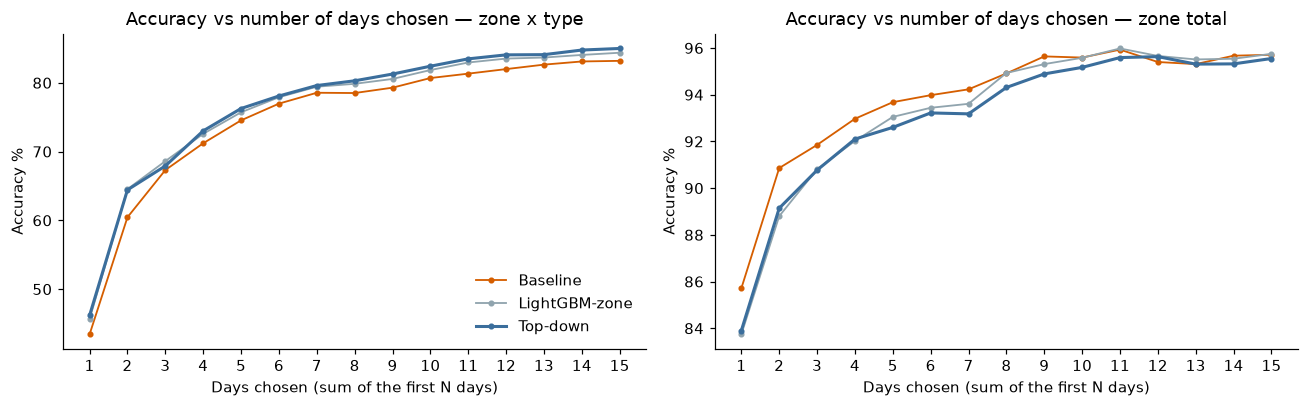

In [21]:
print(f"Accuracy per zone (zone × type), chosen method {ZONE_METHOD}:")
display(zacc[(zacc["level"] == "zone x type") & (zacc["zone"] != "ALL") & (zacc["method"] == ZONE_METHOD)
             & zacc["days"].isin(show_n)].pivot_table(index="zone", columns="days", values="accuracy")
        .join(zone_summary["complaints/day (Jul–Dec)"]))

def exam_acc(n):
    s = zres[zres["h"] <= n].groupby(["exam", "method", "zone_id", "category_id"])[["pred", "actual"]].sum()
    s["err"] = (s["pred"] - s["actual"]).abs()
    g = s.groupby(level=["exam", "method"])
    return (100 * (1 - g["err"].sum() / g["actual"].sum())).unstack()[ZMETHODS].round(1)

for n in (1, 7, 15):
    print(f"Zone × type accuracy per exam, first {n} day(s):")
    display(exam_acc(n))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
colors = {"Baseline": "#D55E00", "LightGBM-zone": "#90A4AE", "Top-down": "#3B6E9C"}
for ax, lvl in zip(axes, ["zone x type", "zone total"]):
    for m in ZMETHODS:
        d = zacc[(zacc["level"] == lvl) & (zacc["zone"] == "ALL") & (zacc["method"] == m)]
        ax.plot(d["days"], d["accuracy"], marker="o", ms=3, color=colors[m], lw=2 if m == ZONE_METHOD else 1.2, label=m)
    ax.set_title(f"Accuracy vs number of days chosen — {lvl}")
    ax.set_xlabel("Days chosen (sum of the first N days)"); ax.set_ylabel("Accuracy %")
    ax.set_xticks(range(1, HORIZON + 1))
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

## 19 · The zone forecast: 1–15 January 2026
<div dir="rtl">

بنستخدم الطريقة الفايزة على كل الداتا (آخر يوم توقف في التدريب 16 ديسمبر)، وبنتوقع من يوم التوقف 31 ديسمبر. والنتيجة لكل منطقة × نوع × يوم من الـ 15، ومعاها مدى الـ 80%.

الملف بيتحفظ بصيغتين: CSV وJSON، عشان أي موقع يقدر يقراه.

</div>

In [22]:
ZONE_CUTOFF = pd.Timestamp("2025-12-31")
final_zone_model = train_zone(pd.Timestamp("2025-12-16"))   # all cutoffs whose 15 target days are known
zfuture = zone_examples(ZONE_CUTOFF)
zmu = {"LightGBM-zone": lambda: final_zone_model.predict(zfuture[ZFEATURES]),
       "Top-down": lambda: top_down(final_model, ZONE_CUTOFF),      # final_model = city model from step 13
       "Baseline": lambda: zfuture["same_dow_4w"].to_numpy()}[ZONE_METHOD]()

zone_forecast = pd.DataFrame({
    "zone": zfuture["zone_id"].astype(str), "date": zfuture["date"].dt.strftime("%Y-%m-%d"),
    "day_number": zfuture["h"], "category_id": zfuture["category_id"].astype(str),
    "pillar": zfuture["category_id"].astype(str).map(PILLAR),
    "forecast": np.round(zmu, 2),
    "low_80": poisson.ppf(0.1, np.maximum(zmu, 1e-9)).astype(int),
    "high_80": poisson.ppf(0.9, np.maximum(zmu, 1e-9)).astype(int),
    "model": ZONE_METHOD}).sort_values(["zone", "day_number", "category_id"], ignore_index=True)
zone_forecast.to_csv(OUT / "zone_forecast_2026-01-01_to_15.csv", index=False)
zone_forecast.to_json(OUT / "zone_forecast_2026-01-01_to_15.json", orient="records", indent=1, force_ascii=False)
print(f"Saved {len(zone_forecast)} rows ({NZ} zones × {NT} types × {HORIZON} days), method {ZONE_METHOD}")
print("Check: zones add up to the city forecast (15-day total):",
      round(zone_forecast["forecast"].sum(), 1), "vs", round(float(mu.sum()), 1))

jan = zone_forecast.pivot_table(index="zone", columns="category_id", values="forecast", aggfunc="sum")
jan["TOTAL"] = jan.sum(axis=1)
jan = jan.sort_values("TOTAL", ascending=False)
jan.loc["ALL"] = jan.sum()
print("Expected complaints, 1–15 Jan 2026, per zone × type:")
jan.round(0).astype(int)

Saved 1350 rows (6 zones × 15 types × 15 days), method Top-down
Check: zones add up to the city forecast (15-day total): 2496.1 vs 2496.3
Expected complaints, 1–15 Jan 2026, per zone × type:


category_id,app,cleanliness,hvac,noise,parking,parks,power_outage,roads,safety,sewer,streetlights,traffic_signals,waste_overflow,water_leak,water_outage,TOTAL
zone,,,,,,,,,,,,,,,,
Z01,22,61,13,40,39,24,36,62,39,44,77,28,69,81,55,690
Z05,19,58,21,61,71,19,32,48,43,37,57,34,76,49,35,660
Z02,23,55,13,32,38,23,43,57,31,39,69,27,69,76,46,642
Z04,7,26,11,17,36,6,13,22,18,11,20,12,29,15,12,254
Z06,8,18,2,20,12,35,5,11,11,4,26,2,21,6,4,182
Z03,3,3,17,1,8,2,2,4,2,2,9,5,5,4,2,68
ALL,81,222,76,172,204,108,131,204,143,136,257,108,269,230,154,2496


## 20 · Save the zone model weights
<div dir="rtl">

- **Top-down** مالوش أوزان جديدة: بيستخدم أوزان موديل المدينة (`model/lightgbm_complaints_forecast.txt`) مع نسب المناطق، اللي بتتحسب من الداتا.
- بنحفظ كمان أوزان **LightGBM-zone** (`model/lightgbm_zone_forecast.txt`) كبديل جاهز، مع بطاقة الموديل.
- السكريبت `model/load_and_predict_zone.py` بيعيد بناء ملف توقع المناطق من الأوزان، من غير تدريب.

</div>

In [23]:
final_zone_model.save_model(str(OUT_MODEL / "lightgbm_zone_forecast.txt"))
zcard = {
    "model_file": "lightgbm_zone_forecast.txt",
    "objective": "poisson", "params": PARAMS, "num_trees": final_zone_model.num_trees(),
    "features": ZFEATURES,
    "categorical_features": ["zone_id", "category_id"],
    "zone_order": ZONES, "category_order": CATS,   # both must be pd.Categorical with exactly these orders
    "pillar": PILLAR[CATS].to_dict(),
    "window_days": WINDOW, "horizon_days": HORIZON, "share_smoothing": 0.5,
    "training_cutoffs": [str(FIRST_CUTOFF.date()), "2025-12-16"],
    "forecast_cutoff": str(ZONE_CUTOFF.date()),
    "weekend_dows": [4, 5],
    "holidays": sorted(str(d.date()) for d in HOLIDAYS),
    "forecast_method": ZONE_METHOD,   # the method that produced outputs/zone_forecast_*.csv
    "top_down": {"city_model_file": "lightgbm_complaints_forecast.txt", "city_model_card": "model_card.json",
                 "share_window_days": 60},
    "versions": {p: version(p) for p in ["lightgbm", "pandas", "numpy", "scipy", "pyarrow"]},
}
(OUT_MODEL / "model_card_zone.json").write_text(json.dumps(zcard, indent=2), encoding="utf-8")
reloaded_z = lgb.Booster(model_file=str(OUT_MODEL / "lightgbm_zone_forecast.txt"))
print("Saved weights:", OUT_MODEL / "lightgbm_zone_forecast.txt")
print("Reloaded zone model gives identical predictions:",
      np.allclose(reloaded_z.predict(zfuture[ZFEATURES]), final_zone_model.predict(zfuture[ZFEATURES])))

Saved weights: C:\Users\NoteBook\Downloads\Capital Project\forecast\model\lightgbm_zone_forecast.txt
Reloaded zone model gives identical predictions: True


## 21 · Choose a zone and a number of days: `get_forecast(zone, days)`
<div dir="rtl">

الدالة موجودة في ملف `forecast_api.py` (جنب النوتبوك)، وبتقرا ملفين بس: ملف التوقع وملف الدقة. فأي موقع أو أي حد يقدر يستخدمها من غير الموديل.

- **المدخلات:**
  - `zone` = `"Z01"` … `"Z06"`، أو `"ALL"` لكل المناطق
  - `days` = أي رقم من 1 لـ 15
- **المخرجات:**
  - `by_type`: كل نوع وعدده المتوقع في الأيام اللي اخترتها، مع المدى، ومترتب من الأكتر للأقل
  - `daily`: كل نوع × كل يوم
  - `total`: الإجمالي مع المدى
  - `accuracy`: دقة الاختيار ده في امتحانات نوفمبر وديسمبر
- **ولو اخترت `"ALL"`:** بيرجع كمان `by_zone` (إجمالي كل منطقة) و`zone_type` (كل منطقة × كل نوع).

</div>

In [24]:
import importlib
import forecast_api
importlib.reload(forecast_api)          # read the files this run just wrote
from forecast_api import get_forecast

def show(r):
    print(f"Zone {r['zone']} · first {r['days']} day(s): {r['dates'][0]} → {r['dates'][1]} · method {r['method']}")
    print(f"Total expected: {r['total']['forecast']} (80% range {r['total']['low_80']}–{r['total']['high_80']})")
    print("Accuracy of this choice in the Nov–Dec tests:", {k: v for k, v in r["accuracy"].items() if k != "measured_on"})
    display(r["by_type"])

# Example 1: zone Z01, next 5 days
r = get_forecast("Z01", days=5)
show(r)
r["daily"]

Zone Z01 · first 5 day(s): 2026-01-01 → 2026-01-05 · method Top-down
Total expected: 223.8 (80% range 205–243)
Accuracy of this choice in the Nov–Dec tests: {'accuracy_%': 81.75, 'mae': 2.89, 'coverage_%': 85.0}


,category_id,pillar,forecast,low_80,high_80
0,water_leak,water,26.6,20,33
1,streetlights,public_safety,25.5,19,32
2,waste_overflow,waste,22.3,16,28
3,roads,mobility,19.9,14,26
4,cleanliness,waste,19.8,14,26
5,water_outage,water,17.7,12,23
6,sewer,water,14.1,9,19
7,noise,environment,12.9,8,18
8,safety,public_safety,12.5,8,17
9,parking,mobility,12.4,8,17


date,2026-01-01,2026-01-02,2026-01-03,2026-01-04,2026-01-05
category_id,,,,,
water_leak,5.8,4.7,4.5,6.0,5.7
streetlights,5.5,4.3,4.3,5.6,5.7
waste_overflow,5.0,3.7,3.5,5.0,5.2
roads,4.5,3.5,3.3,4.2,4.4
cleanliness,4.5,3.3,3.1,4.4,4.5
water_outage,4.0,3.0,2.9,3.8,4.0
sewer,3.2,2.4,2.2,3.4,2.8
noise,2.9,2.2,2.2,2.8,2.8
safety,2.8,2.0,2.0,2.7,3.0


In [25]:
# Example 2: the smallest zone, Z03, all 15 days
show(get_forecast("Z03", days=15))

Zone Z03 · first 15 day(s): 2026-01-01 → 2026-01-15 · method Top-down
Total expected: 68.0 (80% range 58–79)
Accuracy of this choice in the Nov–Dec tests: {'accuracy_%': 61.09, 'mae': 1.78, 'coverage_%': 81.67}


,category_id,pillar,forecast,low_80,high_80
0,hvac,buildings,16.5,11,22
1,streetlights,public_safety,8.7,5,13
2,parking,mobility,7.9,4,12
3,waste_overflow,waste,5.5,3,9
4,traffic_signals,mobility,4.9,2,8
5,roads,mobility,4.2,2,7
6,water_leak,water,3.8,1,6
7,cleanliness,waste,3.0,1,5
8,app,citizen_services,2.7,1,5
9,water_outage,water,2.2,0,4


In [26]:
# Example 3: all zones, next 7 days: where the complaints will come from
r = get_forecast("ALL", days=7)
show(r)
print("Zone totals (most complaints first):")
display(r["by_zone"])
print("Zone × type:")
r["zone_type"]

Zone ALL · first 7 day(s): 2026-01-01 → 2026-01-07 · method Top-down
Total expected: 1146.1 (80% range 1103–1190)
Accuracy of this choice in the Nov–Dec tests: {'accuracy_%': 79.6, 'mae': 2.71, 'coverage_%': 86.11, 'zone_total_accuracy_%': 93.18}


,category_id,pillar,forecast,low_80,high_80
0,waste_overflow,waste,123.0,109,137
1,streetlights,public_safety,117.6,104,132
2,water_leak,water,106.2,93,119
3,cleanliness,waste,100.7,88,114
4,parking,mobility,93.7,81,106
5,roads,mobility,92.8,81,105
6,noise,environment,80.2,69,92
7,water_outage,water,71.0,60,82
8,safety,public_safety,65.7,55,76
9,sewer,water,62.4,52,73


Zone totals (most complaints first):


,zone,forecast,low_80,high_80
0,Z01,316.9,294,340
1,Z05,303.1,281,326
2,Z02,294.5,273,317
3,Z04,116.6,103,130
4,Z06,83.8,72,96
5,Z03,31.3,24,39


Zone × type:


category_id,waste_overflow,streetlights,water_leak,cleanliness,parking,roads,noise,water_outage,safety,sewer,power_outage,parks,traffic_signals,app,hvac
zone,,,,,,,,,,,,,,,
Z01,31.3,35.4,37.4,27.9,17.8,28.1,18.8,25.5,17.8,20.1,16.9,11.2,12.6,10.2,5.9
Z05,34.6,25.9,22.4,26.3,32.7,21.9,28.6,16.2,19.8,16.9,14.6,8.7,15.7,9.0,9.8
Z02,31.7,31.5,35.1,24.8,17.6,26.1,15.0,21.2,14.1,18.0,19.9,10.7,12.4,10.5,5.9
Z04,13.1,9.1,6.8,11.9,16.7,9.9,8.1,5.4,8.3,5.0,5.9,2.6,5.5,3.1,5.2
Z06,9.7,11.7,2.7,8.4,5.3,5.0,9.1,1.7,4.9,1.7,2.2,16.0,1.0,3.5,1.0
Z03,2.5,4.0,1.8,1.4,3.6,1.9,0.7,1.0,0.7,0.8,0.9,0.8,2.2,1.2,7.7


## 22 · Zone summary
<div dir="rtl">

- **بنتوقع:** لكل منطقة (6 مناطق) × نوع (15 نوع) × يوم (1–15) عدد الشكاوى، وتقدر تختار المنطقة وعدد الأيام بـ `get_forecast`.
- **اتمتحنا:** 4 مرات (نوفمبر وديسمبر)، وقارنّا 3 طرق: Baseline وLightGBM-zone وTop-down. والفايزة اتحددت بأعلى متوسط دقة على مستوى المنطقة × النوع (الجدول في خطوة 18).
- **الدقة بتعلى مع عدد الأيام:** يوم واحد لكل نوع في كل منطقة رقمه صغير جدًا (~2 شكوى)، فالصدفة بتأثر جامد. لكن كل ما تختار أيام أكتر، الدقة بتعلى. وإجمالي المنطقة دقته أعلى من كل نوع لوحده.
- **المنطقة Z03 صغيرة جدًا** (~5 شكاوى في اليوم كلها)، فتوقعها لأيام قليلة ضعيف، والأحسن نعرضه على 7–15 يوم.
- **الملفات:**
  - `outputs/zone_forecast_2026-01-01_to_15.csv` و`.json`
  - `outputs/zone_accuracy_by_days.csv`
  - `outputs/zone_backtest.csv`
  - `forecast_api.py`
  - `model/lightgbm_zone_forecast.txt` و`model/model_card_zone.json` و`model/load_and_predict_zone.py`

</div>